<a href="https://colab.research.google.com/github/abusaleh917/Practice/blob/main/coference_paper.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

#Dataset Load

In [33]:
#Install boosting libraries
!pip install xgboost lightgbm catboost -q

In [34]:
#Lode libraries
#core libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

#preprocessing and model selection
from sklearn.preprocessing import LabelEncoder, label_binarize
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score
from sklearn.linear_model import LogisticRegression

#Ensemble Models
from sklearn.ensemble import RandomForestClassifier, ExtraTreesClassifier, StackingClassifier
import xgboost as xgb
import lightgbm as lgb
from catboost import CatBoostClassifier

# Evaluation metrics
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    classification_report, confusion_matrix,
    roc_curve, auc, roc_auc_score,
)

import warnings
warnings.filterwarnings("ignore")

RANDOM_STATE = 20   # same seed everywhere -> reproducible results


In [35]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [36]:
df = pd.read_csv('/content/drive/MyDrive/Colab_Notebooks_Data_Science/UAVIDS-2025.csv')
df.head()

,FlowID,FlowDuration/s,SrcAddr,SrcPort,DstAddr,DstPort,Protocol,TxPackets,RxPackets,LostPackets,...,RxPacketRate/s,TxByteRate/s,RxByteRate/s,MeanDelay/s,MeanJitter/s,Throughput/Kbps,MeanPacketSize,PacketDropRate,AverageHopCount,label
0,1,175.007,192.168.0.150,9,192.168.0.16,9,UDP,251,215,36,...,1.22853,109.002,93.3679,0.022152,0.024406,0.746943,76,0.143426,0.074419,Sybil Attack
1,2,175.008,192.168.0.150,9,192.168.0.19,9,UDP,251,223,28,...,1.27423,109.001,96.8411,0.019637,0.018678,0.774729,76,0.111554,0.053812,Sybil Attack
2,3,175.010,192.168.0.150,9,192.168.0.24,9,UDP,251,224,27,...,1.27993,108.999,97.2744,0.023701,0.023917,0.778195,76,0.107570,0.044643,Sybil Attack
3,4,175.014,192.168.0.150,9,192.168.0.34,9,UDP,251,212,39,...,1.21133,108.997,92.0614,0.034014,0.025408,0.736491,76,0.155378,0.033019,Sybil Attack
4,5,175.017,192.168.0.150,9,192.168.0.39,9,UDP,251,215,36,...,1.22845,108.995,93.3623,0.034396,0.024933,0.746899,76,0.143426,0.009302,Sybil Attack


In [37]:
#column type and missing value
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 122171 entries, 0 to 122170
Data columns (total 23 columns):
 #   Column           Non-Null Count   Dtype  
---  ------           --------------   -----  
 0   FlowID           122171 non-null  int64  
 1   FlowDuration/s   122171 non-null  float64
 2   SrcAddr          122171 non-null  object 
 3   SrcPort          122171 non-null  int64  
 4   DstAddr          122171 non-null  object 
 5   DstPort          122171 non-null  int64  
 6   Protocol         122171 non-null  object 
 7   TxPackets        122171 non-null  int64  
 8   RxPackets        122171 non-null  int64  
 9   LostPackets      122171 non-null  int64  
 10  TxBytes          122171 non-null  int64  
 11  RxBytes          122171 non-null  int64  
 12  TxPacketRate/s   122171 non-null  float64
 13  RxPacketRate/s   122171 non-null  float64
 14  TxByteRate/s     122171 non-null  float64
 15  RxByteRate/s     122171 non-null  float64
 16  MeanDelay/s      122171 non-null  floa

In [38]:
# Summary statistics of numeric columns
df.describe()

,FlowID,FlowDuration/s,SrcPort,DstPort,TxPackets,RxPackets,LostPackets,TxBytes,RxBytes,TxPacketRate/s,RxPacketRate/s,TxByteRate/s,RxByteRate/s,MeanDelay/s,MeanJitter/s,Throughput/Kbps,MeanPacketSize,PacketDropRate,AverageHopCount
count,122171.000000,122171.000000,122171.000000,122171.000000,122171.000000,122171.000000,122171.000000,1.221710e+05,1.221710e+05,122171.000000,122171.000000,1.221710e+05,122171.000000,122171.000000,122171.000000,122171.000000,122171.000000,122171.000000,122171.000000
mean,61086.000000,696.714475,169.137348,169.137348,486.930368,426.070737,60.436159,3.587245e+04,3.193820e+04,2.466915,1.383054,1.820916e+02,103.422636,0.207858,0.140080,0.827381,68.122885,0.369328,0.264616
std,35267.874206,780.052068,278.648982,278.648982,1933.094801,1367.693106,1149.330904,1.246644e+05,1.025546e+05,130.044753,58.987416,9.857745e+03,4481.638475,0.454055,0.306921,35.853110,13.838427,0.309535,0.653093
min,1.000000,0.000076,9.000000,9.000000,1.000000,0.000000,0.000000,3.000000e+01,0.000000e+00,0.001197,0.000000,4.467260e-02,0.000000,0.000000,0.000000,0.000000,30.000000,0.000000,0.000000
25%,30543.500000,124.722000,9.000000,9.000000,14.000000,5.000000,4.000000,9.820000e+02,3.800000e+02,0.045725,0.017262,3.015870e+00,1.087125,0.019264,0.007475,0.008697,76.000000,0.090909,0.000000
50%,61086.000000,227.867000,9.000000,9.000000,51.000000,23.000000,12.000000,2.964000e+03,1.376000e+03,0.205224,0.068020,1.381560e+01,3.957470,0.058348,0.043962,0.031660,76.000000,0.285714,0.028815
75%,91628.500000,1415.655000,9.000000,9.000000,280.000000,196.000000,50.000000,1.877200e+04,1.413600e+04,1.430270,1.255630,1.086920e+02,95.359300,0.196488,0.138670,0.762875,76.000000,0.642857,0.187500
max,122171.000000,10591.800000,654.000000,654.000000,220886.000000,63653.000000,212557.000000,1.126508e+07,3.246018e+06,33116.600000,13115.800000,2.516860e+06,996800.000000,10.168500,6.717600,7974.400000,76.000000,1.333330,58.000000


In [39]:
# Print the distribution of the target variable to see the different attack / normal classes
class_counts = df['label'].value_counts()
display(class_counts.to_frame())

,count
label,
Normal Traffic,26172
Blackhole Attack,26110
Wormhole Attack,26086
Sybil Attack,24077
Flooding Attack,19726


In [40]:
# Exact duplicate rows
print("Exact duplicate rows:", df.duplicated().sum())

# Duplicate feature records
X = df.drop(columns=['label'])

print(
    "Duplicate feature rows:",
    X.duplicated().sum()
)

Exact duplicate rows: 0
Duplicate feature rows: 0


In [41]:
identifier_cols = [
    "FlowID",
    "SrcAddr",
    "DstAddr",
    "SrcPort",
    "DstPort"
]

for col in identifier_cols:
    if col in df.columns:
        print(
            col,
            "Unique values:",
            df[col].nunique(),
            "Total values:",
            len(df)
        )

FlowID Unique values: 122171 Total values: 122171
SrcAddr Unique values: 176 Total values: 122171
DstAddr Unique values: 218 Total values: 122171
SrcPort Unique values: 2 Total values: 122171
DstPort Unique values: 2 Total values: 122171


In [42]:
print(pd.crosstab(df["SrcPort"], df['label']))

print(pd.crosstab(
    df["SrcPort"],
    df['label'],
    normalize="index"
).round(3))

print(pd.crosstab(
    df["DstPort"],
    df['label'],
    normalize="index"
).round(3))

label    Blackhole Attack  Flooding Attack  Normal Traffic  Sybil Attack  \
SrcPort                                                                    
9                   11248            19726           11294         24077   
654                 14862                0           14878             0   

label    Wormhole Attack  
SrcPort                   
9                  25494  
654                  592  
label    Blackhole Attack  Flooding Attack  Normal Traffic  Sybil Attack  \
SrcPort                                                                    
9                   0.122            0.215           0.123         0.262   
654                 0.490            0.000           0.491         0.000   

label    Wormhole Attack  
SrcPort                   
9                  0.278  
654                0.020  
label    Blackhole Attack  Flooding Attack  Normal Traffic  Sybil Attack  \
DstPort                                                                    
9                   0.

In [43]:
# Define the columns to exclude from features
exclude_cols = ['FlowID', 'DstPort', 'label']

# Prepare features (X) and target (y)
X = df.drop(columns=[col for col in exclude_cols if col in df.columns])
y = df['label']

# Display shapes and heads
print("X shape:", X.shape)
print("y shape:", y.shape)
display(X.head())

X shape: (122171, 20)
y shape: (122171,)


,FlowDuration/s,SrcAddr,SrcPort,DstAddr,Protocol,TxPackets,RxPackets,LostPackets,TxBytes,RxBytes,TxPacketRate/s,RxPacketRate/s,TxByteRate/s,RxByteRate/s,MeanDelay/s,MeanJitter/s,Throughput/Kbps,MeanPacketSize,PacketDropRate,AverageHopCount
0,175.007,192.168.0.150,9,192.168.0.16,UDP,251,215,36,19076,16340,1.43423,1.22853,109.002,93.3679,0.022152,0.024406,0.746943,76,0.143426,0.074419
1,175.008,192.168.0.150,9,192.168.0.19,UDP,251,223,28,19076,16948,1.43422,1.27423,109.001,96.8411,0.019637,0.018678,0.774729,76,0.111554,0.053812
2,175.010,192.168.0.150,9,192.168.0.24,UDP,251,224,27,19076,17024,1.43420,1.27993,108.999,97.2744,0.023701,0.023917,0.778195,76,0.107570,0.044643
3,175.014,192.168.0.150,9,192.168.0.34,UDP,251,212,39,19076,16112,1.43417,1.21133,108.997,92.0614,0.034014,0.025408,0.736491,76,0.155378,0.033019
4,175.017,192.168.0.150,9,192.168.0.39,UDP,251,215,36,19076,16340,1.43415,1.22845,108.995,93.3623,0.034396,0.024933,0.746899,76,0.143426,0.009302


In [44]:
# Perform 80:20 stratified train-test split
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    stratify=y,
    random_state=RANDOM_STATE
)

# Output split sizes and class distributions to verify stratification
print(f"X_train shape: {X_train.shape}")
print(f"X_test shape: {X_test.shape}")
print("\nTrain class distribution (relative):\n", y_train.value_counts(normalize=True).round(4))
print("\nTest class distribution (relative):\n", y_test.value_counts(normalize=True).round(4))

X_train shape: (97736, 20)
X_test shape: (24435, 20)

Train class distribution (relative):
 label
Normal Traffic      0.2142
Blackhole Attack    0.2137
Wormhole Attack     0.2135
Sybil Attack        0.1971
Flooding Attack     0.1615
Name: proportion, dtype: float64

Test class distribution (relative):
 label
Normal Traffic      0.2142
Blackhole Attack    0.2137
Wormhole Attack     0.2135
Sybil Attack        0.1971
Flooding Attack     0.1614
Name: proportion, dtype: float64


In [45]:
# Identify categorical columns to encode
categorical_cols = ['SrcAddr', 'DstAddr', 'Protocol']

# Encode categorical columns using LabelEncoder
label_encoders = {}
for col in categorical_cols:
    le = LabelEncoder()
    # Fit on training data and transform both train and test sets
    # Using map / handling unseen values dynamically if necessary, but fit/transform is standard
    X_train[col] = le.fit_transform(X_train[col].astype(str))

    # For test set, mapping unseen labels to a placeholder if any exist
    # (Normally we can use a lookup dictionary or map)
    le_dict = dict(zip(le.classes_, le.transform(le.classes_)))
    X_test[col] = X_test[col].astype(str).map(le_dict).fillna(-1).astype(int)

    label_encoders[col] = le

# Also encode the target labels (y) to integers for models that require numeric classes
target_encoder = LabelEncoder()
y_train_encoded = target_encoder.fit_transform(y_train)
y_test_encoded = target_encoder.transform(y_test)

print("Encoded target classes mapping:")
for idx, class_name in enumerate(target_encoder.classes_):
    print(f"{class_name} -> {idx}")

# Display a preview of the processed features
display(X_train.head())

Encoded target classes mapping:
Blackhole Attack -> 0
Flooding Attack -> 1
Normal Traffic -> 2
Sybil Attack -> 3
Wormhole Attack -> 4


,FlowDuration/s,SrcAddr,SrcPort,DstAddr,Protocol,TxPackets,RxPackets,LostPackets,TxBytes,RxBytes,TxPacketRate/s,RxPacketRate/s,TxByteRate/s,RxByteRate/s,MeanDelay/s,MeanJitter/s,Throughput/Kbps,MeanPacketSize,PacketDropRate,AverageHopCount
52894,167.4040,64,9,171,0,434,401,33,32984,30476,2.592530,2.395410,197.033000,182.051000,0.038459,0.040258,1.456410,76,0.076037,0.004988
64535,1777.1300,96,654,74,0,34,34,0,1552,1552,0.019132,0.019132,0.873316,0.873316,0.005040,0.005514,0.006987,45,0.000000,0.000000
105035,195.0050,14,9,176,0,54,22,32,4104,1672,0.276917,0.112818,21.045700,8.574160,0.160881,0.123222,0.068593,76,0.592593,0.000000
40980,72.4056,160,9,193,0,11,5,6,836,380,0.151922,0.069055,11.546100,5.248210,0.349227,0.266044,0.041986,76,0.545455,0.400000
105343,195.2100,38,9,146,0,55,13,42,4180,988,0.281748,0.066595,21.412800,5.061220,0.378091,0.383907,0.040490,76,0.763636,0.076923


In [46]:
# Initialize Extra Trees Classifier
et_model = ExtraTreesClassifier(
    n_estimators=100,
    random_state=RANDOM_STATE,
    n_jobs=-1
)

# Train the model
et_model.fit(X_train, y_train_encoded)

# Predict on test set
y_pred_et = et_model.predict(X_test)

# Generate classification report
print("--- Extra Trees Classification Report ---")
print(classification_report(y_test_encoded, y_pred_et, target_names=target_encoder.classes_))

--- Extra Trees Classification Report ---
                  precision    recall  f1-score   support

Blackhole Attack       0.93      0.88      0.90      5222
 Flooding Attack       1.00      1.00      1.00      3945
  Normal Traffic       0.99      0.99      0.99      5235
    Sybil Attack       1.00      1.00      1.00      4816
 Wormhole Attack       0.87      0.93      0.90      5217

        accuracy                           0.95     24435
       macro avg       0.96      0.96      0.96     24435
    weighted avg       0.96      0.95      0.96     24435



In [47]:
# Alias the trained Extra Trees model as model_A
model_A = et_model
print("model_A is successfully defined and ready.")

model_A is successfully defined and ready.


In [48]:
# Generate predictions using model_A on the test set
y_pred_A = model_A.predict(X_test)

# Display the array of predictions
print("Predictions generated successfully!")
print("First 10 predictions (encoded):", y_pred_A[:10])
print("First 10 predictions (original labels):", target_encoder.inverse_transform(y_pred_A[:10]))

Predictions generated successfully!
First 10 predictions (encoded): [0 4 4 1 2 2 1 0 3 0]
First 10 predictions (original labels): ['Blackhole Attack' 'Wormhole Attack' 'Wormhole Attack' 'Flooding Attack'
 'Normal Traffic' 'Normal Traffic' 'Flooding Attack' 'Blackhole Attack'
 'Sybil Attack' 'Blackhole Attack']


In [49]:
from sklearn.metrics import accuracy_score, f1_score

# Calculate metrics
accuracy_A = accuracy_score(y_test_encoded, y_pred_A)
macro_f1_A = f1_score(y_test_encoded, y_pred_A, average='macro')
weighted_f1_A = f1_score(y_test_encoded, y_pred_A, average='weighted')

# Print metrics formatted to 4 decimal places
print(f"Model A Evaluation Metrics:")
print(f"Accuracy:    {accuracy_A:.4f}")
print(f"Macro F1:    {macro_f1_A:.4f}")
print(f"Weighted F1: {weighted_f1_A:.4f}")

Model A Evaluation Metrics:
Accuracy:    0.9550
Macro F1:    0.9577
Weighted F1: 0.9550


In [50]:
import time

# Measure Training Time
start_train = time.time()
et_model_time = ExtraTreesClassifier(
    n_estimators=100,
    random_state=RANDOM_STATE,
    n_jobs=-1
)
et_model_time.fit(X_train, y_train_encoded)
end_train = time.time()
training_time = end_train - start_train

# Measure Inference Time
start_infer = time.time()
_ = et_model_time.predict(X_test)
end_infer = time.time()
inference_time = end_infer - start_infer

print(f"Model A (Extra Trees) Execution Profile:")
print(f"Training Time:  {training_time:.4f} seconds")
print(f"Inference Time: {inference_time:.4f} seconds")

Model A (Extra Trees) Execution Profile:
Training Time:  10.4930 seconds
Inference Time: 0.9286 seconds


In [51]:
# Define features to exclude for Model B
exclude_cols_B = ['SrcPort', 'SrcAddr', 'DstAddr']

# Drop these columns from our already encoded training and testing sets
X_train_B = X_train.drop(columns=exclude_cols_B)
X_test_B = X_test.drop(columns=exclude_cols_B)

print("Model B Feature Set Shape:")
print(f"X_train_B shape: {X_train_B.shape}")
print(f"X_test_B shape:  {X_test_B.shape}")
print("Features used:", list(X_train_B.columns))

Model B Feature Set Shape:
X_train_B shape: (97736, 17)
X_test_B shape:  (24435, 17)
Features used: ['FlowDuration/s', 'Protocol', 'TxPackets', 'RxPackets', 'LostPackets', 'TxBytes', 'RxBytes', 'TxPacketRate/s', 'RxPacketRate/s', 'TxByteRate/s', 'RxByteRate/s', 'MeanDelay/s', 'MeanJitter/s', 'Throughput/Kbps', 'MeanPacketSize', 'PacketDropRate', 'AverageHopCount']


In [52]:
# ==========================================
# MODEL B: REUSE MODEL A SPLIT (VERIFICATION)
# ==========================================

# Using the correctly subsetted DataFrames from cell f41bbd4b
print("Model B Feature Set Shape Verification:")
print("Training shape:", X_train_B.shape)
print("Testing shape:", X_test_B.shape)

print("\nTraining records:", len(y_train_encoded))
print("Testing records:", len(y_test_encoded))

Model B Feature Set Shape Verification:
Training shape: (97736, 17)
Testing shape: (24435, 17)

Training records: 97736
Testing records: 24435


In [53]:
import time
from sklearn.metrics import accuracy_score, f1_score, classification_report

# Initialize and train Model B (Extra Trees Classifier with reduced feature set)
model_B = ExtraTreesClassifier(
    n_estimators=100,
    random_state=RANDOM_STATE,
    n_jobs=-1
)

start_train_B = time.time()
model_B.fit(X_train_B, y_train_encoded)
training_time_B = time.time() - start_train_B

# Measure Inference Time
start_infer_B = time.time()
y_pred_B = model_B.predict(X_test_B)
inference_time_B = time.time() - start_infer_B

# Calculate evaluation metrics
accuracy_B = accuracy_score(y_test_encoded, y_pred_B)
macro_f1_B = f1_score(y_test_encoded, y_pred_B, average='macro')
weighted_f1_B = f1_score(y_test_encoded, y_pred_B, average='weighted')

print("--- Model B (Reduced Features) Evaluation ---")
print(f"Training Time:  {training_time_B:.4f} seconds")
print(f"Inference Time: {inference_time_B:.4f} seconds")
print(f"Accuracy:    {accuracy_B:.4f}")
print(f"Macro F1:    {macro_f1_B:.4f}")
print(f"Weighted F1: {weighted_f1_B:.4f}")

print("\nClassification Report:")
print(classification_report(y_test_encoded, y_pred_B, target_names=target_encoder.classes_))

--- Model B (Reduced Features) Evaluation ---
Training Time:  8.5416 seconds
Inference Time: 0.9971 seconds
Accuracy:    0.9497
Macro F1:    0.9527
Weighted F1: 0.9498

Classification Report:
                  precision    recall  f1-score   support

Blackhole Attack       0.91      0.89      0.90      5222
 Flooding Attack       1.00      0.99      0.99      3945
  Normal Traffic       0.99      0.99      0.99      5235
    Sybil Attack       1.00      1.00      1.00      4816
 Wormhole Attack       0.87      0.90      0.89      5217

        accuracy                           0.95     24435
       macro avg       0.95      0.95      0.95     24435
    weighted avg       0.95      0.95      0.95     24435



In [54]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Create a comparison table
metrics_data = {
    'Metric': ['Accuracy', 'Macro F1', 'Weighted F1', 'Training Time (s)', 'Inference Time (s)'],
    'Model A (All Features)': [accuracy_A, macro_f1_A, weighted_f1_A, training_time, inference_time],
    'Model B (No IP/Port)': [accuracy_B, macro_f1_B, weighted_f1_B, training_time_B, inference_time_B]
}

comparison_df = pd.DataFrame(metrics_data)
display(comparison_df.round(4))


,Metric,Model A (All Features),Model B (No IP/Port)
0,Accuracy,0.9550,0.9497
1,Macro F1,0.9577,0.9527
2,Weighted F1,0.9550,0.9498
3,Training Time (s),10.4930,8.5416
4,Inference Time (s),0.9286,0.9971


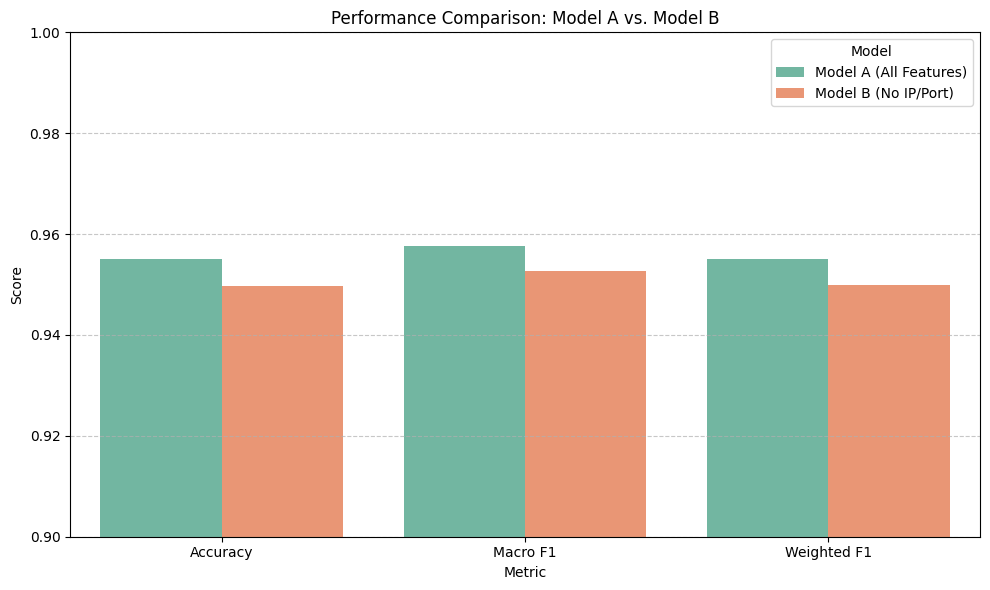

In [107]:
# Plot comparison of predictive performance metrics
plot_data = pd.melt(comparison_df.iloc[:3], id_vars=['Metric'], var_name='Model', value_name='Value')

plt.figure(figsize=(10, 6))
sns.barplot(x='Metric', y='Value', hue='Model', data=plot_data, palette='Set2')
plt.ylim(0.9, 1.0)
plt.title('Performance Comparison: Model A vs. Model B')
plt.ylabel('Score')
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()

In [6]:
# ==========================================
# EXPERIMENT 3: MI TOP-K FEATURE SELECTION
# UAVIDS-2025
# ==========================================
import pandas as pd
from sklearn.feature_selection import mutual_info_classif
from sklearn.preprocessing import OrdinalEncoder
from sklearn.impute import SimpleImputer

# Ensure preceding cells defining X_train_B and y_train are run first!
X_mi = X_train_B.copy()

cat_cols = X_mi.select_dtypes(
    include=["object", "category", "bool"]
).columns.tolist()

num_cols = X_mi.select_dtypes(
    include=["number"]
).columns.tolist()

# Impute numerical features
num_imputer = SimpleImputer(strategy="median")

if num_cols:
    X_mi[num_cols] = num_imputer.fit_transform(
        X_mi[num_cols]
    )

# Encode categorical features
if cat_cols:
    cat_imputer = SimpleImputer(strategy="most_frequent")
    X_cat = cat_imputer.fit_transform(X_mi[cat_cols])

    encoder = OrdinalEncoder(
        handle_unknown="use_encoded_value",
        unknown_value=-1
    )

    X_mi[cat_cols] = encoder.fit_transform(X_cat)

# Calculate MI scores
discrete_mask = [
    col in cat_cols for col in X_mi.columns
]

mi_scores = mutual_info_classif(
    X_mi,
    y_train,
    discrete_features=discrete_mask,
    random_state=42,
    n_jobs=-1
)

# Feature ranking
mi_ranking = pd.DataFrame({
    "Feature": X_mi.columns,
    "MI_Score": mi_scores
}).sort_values(
    "MI_Score",
    ascending=False
).reset_index(drop=True)

print("MUTUAL INFORMATION FEATURE RANKING")
print(mi_ranking.to_string(index=False))

NameError: name 'X_train_B' is not defined